In [ ]:
import os, math, json, time, gc, glob, random, tarfile, pathlib, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix, classification_report
from IPython.display import display

SEED = 42
IMG_SIZE = 224
BATCH = 32
NUM_CLASSES = 5
EPOCHS_HEAD = 8        # phase 1: backbone frozen, lr = LR_HEAD
EPOCHS_FT = 7          # phase 2: conv5_x unfrozen, lr = LR_FT
LR_HEAD = 1e-3
LR_FT = 1e-4
DROPOUT = 0.3

WORK = '/content'
WEIGHT_DIR = f'{WORK}/weights'
FIG_DIR = f'{WORK}/figures'
RESULTS_PATH = f'{WORK}/results.json'
os.makedirs(WEIGHT_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

random.seed(SEED); np.random.seed(SEED); keras.utils.set_random_seed(SEED)

print('TensorFlow:', tf.__version__, '| Keras:', getattr(keras, '__version__', 'tf.keras'))
gpus = tf.config.list_physical_devices('GPU')
print('GPUs:', gpus)
if not gpus:
    print('WARNING: no GPU found. Runtime > Change runtime type > GPU')

def savefig(name):
    plt.savefig(f'{FIG_DIR}/{name}.png', dpi=150, bbox_inches='tight')

TensorFlow: 2.21.0 | Keras: 3.13.2
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
URL = 'https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz'
DATA_ROOT = f'{WORK}/flower_photos'

if not os.path.isdir(DATA_ROOT):
    tgz = f'{WORK}/flower_photos.tgz'
    urllib.request.urlretrieve(URL, tgz)
    with tarfile.open(tgz) as tar:
        try:
            tar.extractall(WORK, filter='data')
        except TypeError:
            tar.extractall(WORK)

CLASS_NAMES = sorted([d.name for d in pathlib.Path(DATA_ROOT).iterdir() if d.is_dir()])
print('Classes:', CLASS_NAMES)
assert len(CLASS_NAMES) == NUM_CLASSES

paths, labels = [], []
for i, c in enumerate(CLASS_NAMES):
    fs = sorted(glob.glob(f'{DATA_ROOT}/{c}/*.jpg'))
    paths += fs
    labels += [i] * len(fs)
print('Total images:', len(paths))

tr_p, tmp_p, tr_y, tmp_y = train_test_split(paths, labels, test_size=0.30, stratify=labels, random_state=SEED)
va_p, te_p, va_y, te_y = train_test_split(tmp_p, tmp_y, test_size=0.50, stratify=tmp_y, random_state=SEED)

print(f'Train: {len(tr_p)} | Val: {len(va_p)} | Test: {len(te_p)}')
split_df = pd.DataFrame({
    'class': CLASS_NAMES,
    'train': [tr_y.count(i) for i in range(NUM_CLASSES)],
    'val': [va_y.count(i) for i in range(NUM_CLASSES)],
    'test': [te_y.count(i) for i in range(NUM_CLASSES)],
})
display(split_df)

with open(f'{WORK}/split.json', 'w') as f:
    json.dump({'train': tr_p, 'val': va_p, 'test': te_p}, f)

Classes: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']
Total images: 3670
Train: 2569 | Val: 550 | Test: 551


,class,train,val,test
0,daisy,443,95,95
1,dandelion,629,134,135
2,roses,449,96,96
3,sunflowers,489,105,105
4,tulips,559,120,120


X_test: (551, 224, 224, 3) | y_test: (551,)


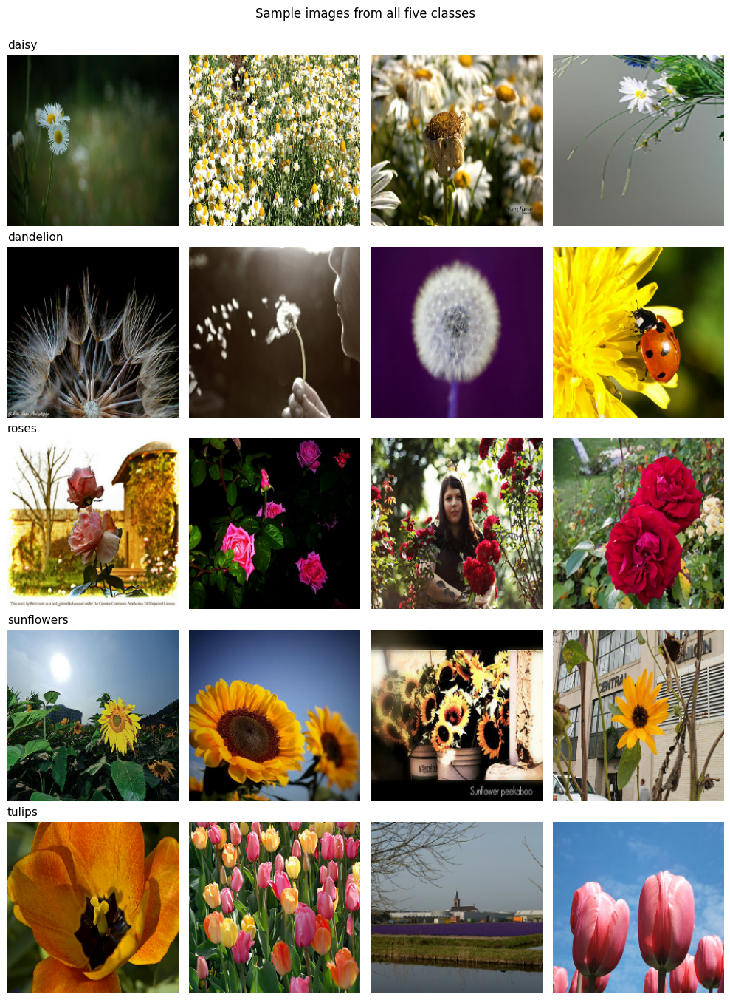

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

def load_img(path):
    b = tf.io.read_file(path)
    img = tf.io.decode_jpeg(b, channels=3)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    return tf.saturate_cast(tf.round(img), tf.uint8)

def make_ds(p, l, training):
    y = tf.one_hot(tf.constant(l), NUM_CLASSES)
    ds = tf.data.Dataset.from_tensor_slices((tf.constant(p), y))
    ds = ds.map(lambda a, b: (load_img(a), b), num_parallel_calls=AUTOTUNE)
    ds = ds.cache()
    if training:
        ds = ds.shuffle(len(p), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH)
    ds = ds.map(lambda a, b: (tf.cast(a, tf.float32), b), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

train_ds = make_ds(tr_p, tr_y, True)
val_ds = make_ds(va_p, va_y, False)
test_ds = make_ds(te_p, te_y, False)

X_test = np.concatenate([x.numpy() for x, _ in test_ds]).astype(np.uint8)
y_test = np.array(te_y)
print('X_test:', X_test.shape, '| y_test:', y_test.shape)

# one fixed test image per class, reused in the visualisations
REP_IDX = [int(np.where(y_test == c)[0][0]) for c in range(NUM_CLASSES)]

# Visualization 1: sample images from all five classes
fig, axes = plt.subplots(NUM_CLASSES, 4, figsize=(10, 2.7 * NUM_CLASSES))
rng = np.random.RandomState(SEED)
for c in range(NUM_CLASSES):
    cls_paths = [p for p, l in zip(tr_p, tr_y) if l == c]
    for j, p in enumerate(rng.choice(cls_paths, 4, replace=False)):
        axes[c][j].imshow(load_img(str(p)).numpy())
        axes[c][j].axis('off')
        if j == 0:
            axes[c][j].set_title(CLASS_NAMES[c], loc='left', fontsize=11)
plt.suptitle('Sample images from all five classes', y=1.0)
plt.tight_layout()
savefig('01_sample_images')
plt.show()

In [ ]:
# ---------------- custom helper layers ----------------
class CaffePreprocess(layers.Layer):
    """ResNet50 (ImageNet) preprocessing: RGB->BGR and mean subtraction."""
    def call(self, x):
        x = tf.cast(x, tf.float32)
        x = x[..., ::-1]
        return x - tf.constant([103.939, 116.779, 123.68], dtype=tf.float32)
    def compute_output_shape(self, input_shape):
        return input_shape

class ChannelPool(layers.Layer):
    """[mean over channels || max over channels] -> H x W x 2"""
    def call(self, x):
        return tf.concat([tf.reduce_mean(x, axis=-1, keepdims=True),
                          tf.reduce_max(x, axis=-1, keepdims=True)], axis=-1)
    def compute_output_shape(self, input_shape):
        s = list(input_shape); s[-1] = 2
        return tuple(s)

class AxisMean(layers.Layer):
    def __init__(self, ax, **kw):
        super().__init__(**kw)
        self.ax = ax
    def call(self, x):
        return tf.reduce_mean(x, axis=self.ax, keepdims=True)
    def compute_output_shape(self, input_shape):
        s = list(input_shape); s[self.ax] = 1
        return tuple(s)

class SelfAttention2D(layers.Layer):
    """Q,K,V self-attention over H*W positions; F_SA = F + gamma * reshape(softmax(QK^T/sqrt(d)) V)"""
    def build(self, input_shape):
        shp = tuple(input_shape)
        self.h, self.w, self.c = int(shp[1]), int(shp[2]), int(shp[3])
        self.dk = max(self.c // 8, 8)
        self.q = layers.Conv2D(self.dk, 1, name=f'{self.name}_q')
        self.k = layers.Conv2D(self.dk, 1, name=f'{self.name}_k')
        self.v = layers.Conv2D(self.c, 1, name=f'{self.name}_v')
        for l in (self.q, self.k, self.v):
            l.build(shp)
        self.gamma = self.add_weight(name='gamma', shape=(1,), initializer='zeros', trainable=True)
        super().build(input_shape)

    def attention_matrix(self, x):
        n = self.h * self.w
        q = tf.reshape(self.q(x), (-1, n, self.dk))
        k = tf.reshape(self.k(x), (-1, n, self.dk))
        return tf.nn.softmax(tf.matmul(q, k, transpose_b=True) / math.sqrt(self.dk), axis=-1)

    def call(self, x):
        n = self.h * self.w
        a = self.attention_matrix(x)
        v = tf.reshape(self.v(x), (-1, n, self.c))
        y = tf.reshape(tf.matmul(a, v), (-1, self.h, self.w, self.c))
        return x + self.gamma * y

    def compute_output_shape(self, input_shape):
        return input_shape

# ---------------- attention blocks (every layer name starts with the tag, e.g. 'attP3') ----------------
def _ch(x, tag, r=16):
    C = x.shape[-1]
    z = layers.GlobalAveragePooling2D(keepdims=True, name=f'{tag}_ch_gap')(x)
    z = layers.Conv2D(max(C // r, 1), 1, activation='relu', name=f'{tag}_ch_fc1')(z)
    m = layers.Conv2D(C, 1, activation='sigmoid', name=f'{tag}_chan_map')(z)
    return layers.Multiply(name=f'{tag}_ch_mul')([x, m])

def _sp(x, tag, k=7):
    s = ChannelPool(name=f'{tag}_chpool')(x)
    m = layers.Conv2D(1, k, padding='same', activation='sigmoid', name=f'{tag}_sp_map')(s)
    return layers.Multiply(name=f'{tag}_sp_mul')([x, m])

def _sa(x, tag):
    return SelfAttention2D(name=f'{tag}_self')(x)

def _eca(x, tag):
    C = x.shape[-1]
    t = int(abs((math.log2(C) + 1) / 2))
    ks = t if t % 2 else t + 1
    z = layers.GlobalAveragePooling2D(keepdims=True, name=f'{tag}_eca_gap')(x)
    z = layers.Reshape((C, 1), name=f'{tag}_eca_r1')(z)
    z = layers.Conv1D(1, ks, padding='same', use_bias=False, activation='sigmoid', name=f'{tag}_eca_conv')(z)
    m = layers.Reshape((1, 1, C), name=f'{tag}_chan_map')(z)
    return layers.Multiply(name=f'{tag}_eca_mul')([x, m])

def _cbam(x, tag, r=16, k=7):
    C = x.shape[-1]
    ga = layers.GlobalAveragePooling2D(keepdims=True, name=f'{tag}_cb_gap')(x)
    gm = layers.GlobalMaxPooling2D(keepdims=True, name=f'{tag}_cb_gmp')(x)
    f1 = layers.Conv2D(max(C // r, 1), 1, activation='relu', name=f'{tag}_cb_fc1')
    f2 = layers.Conv2D(C, 1, name=f'{tag}_cb_fc2')
    s = layers.Add(name=f'{tag}_cb_add')([f2(f1(ga)), f2(f1(gm))])
    m = layers.Activation('sigmoid', name=f'{tag}_chan_map')(s)
    x = layers.Multiply(name=f'{tag}_cb_mul')([x, m])
    return _sp(x, tag, k)

def _coord(x, tag, r=32):
    C, H, W = x.shape[-1], x.shape[1], x.shape[2]
    mip = max(8, C // r)
    ph = AxisMean(2, name=f'{tag}_co_poolh')(x)                      # B,H,1,C
    pw = AxisMean(1, name=f'{tag}_co_poolw')(x)                      # B,1,W,C
    pw = layers.Permute((2, 1, 3), name=f'{tag}_co_perm1')(pw)       # B,W,1,C
    y = layers.Concatenate(axis=1, name=f'{tag}_co_cat')([ph, pw])   # B,H+W,1,C
    y = layers.Conv2D(mip, 1, name=f'{tag}_co_conv1')(y)
    y = layers.BatchNormalization(name=f'{tag}_co_bn')(y)
    y = layers.Activation('swish', name=f'{tag}_co_act')(y)
    yh = layers.Cropping2D(((0, W), (0, 0)), name=f'{tag}_co_crop_h')(y)   # B,H,1,mip
    yw = layers.Cropping2D(((H, 0), (0, 0)), name=f'{tag}_co_crop_w')(y)   # B,W,1,mip
    yw = layers.Permute((2, 1, 3), name=f'{tag}_co_perm2')(yw)             # B,1,W,mip
    ah = layers.Conv2D(C, 1, activation='sigmoid', name=f'{tag}_co_ah')(yh)
    aw = layers.Conv2D(C, 1, activation='sigmoid', name=f'{tag}_co_aw')(yw)
    x = layers.Multiply(name=f'{tag}_co_mul1')([x, ah])
    return layers.Multiply(name=f'{tag}_co_mul2')([x, aw])

def add_attention(x, kind, tag, k=7):
    if kind == 'channel':    x = _ch(x, tag)
    elif kind == 'spatial':  x = _sp(x, tag, k)
    elif kind == 'cs':       x = _sp(_ch(x, tag), tag, k)            # channel -> spatial
    elif kind == 'sc':       x = _ch(_sp(x, tag, k), tag)            # spatial -> channel
    elif kind == 'self':     x = _sa(x, tag)
    elif kind == 'combined': x = _sa(_sp(_ch(x, tag), tag, k), tag)  # channel -> spatial -> self
    elif kind == 'eca':      x = _eca(x, tag)
    elif kind == 'cbam':     x = _cbam(x, tag, k=7)
    elif kind == 'coord':    x = _coord(x, tag)
    else: raise ValueError(kind)
    return layers.Activation('linear', name=f'{tag}_post')(x)

# ---------------- ResNet50 (same layer names as keras.applications) ----------------
def res_block(x, filters, stride=1, conv_shortcut=True, name=None):
    if conv_shortcut:
        sc = layers.Conv2D(4 * filters, 1, strides=stride, name=f'{name}_0_conv')(x)
        sc = layers.BatchNormalization(epsilon=1.001e-5, name=f'{name}_0_bn')(sc)
    else:
        sc = x
    x = layers.Conv2D(filters, 1, strides=stride, name=f'{name}_1_conv')(x)
    x = layers.BatchNormalization(epsilon=1.001e-5, name=f'{name}_1_bn')(x)
    x = layers.Activation('relu', name=f'{name}_1_relu')(x)
    x = layers.Conv2D(filters, 3, padding='same', name=f'{name}_2_conv')(x)
    x = layers.BatchNormalization(epsilon=1.001e-5, name=f'{name}_2_bn')(x)
    x = layers.Activation('relu', name=f'{name}_2_relu')(x)
    x = layers.Conv2D(4 * filters, 1, name=f'{name}_3_conv')(x)
    x = layers.BatchNormalization(epsilon=1.001e-5, name=f'{name}_3_bn')(x)
    x = layers.Add(name=f'{name}_add')([sc, x])
    return layers.Activation('relu', name=f'{name}_out')(x)

def res_stack(x, filters, blocks, stride1, name):
    x = res_block(x, filters, stride1, True, f'{name}_block1')
    for i in range(2, blocks + 1):
        x = res_block(x, filters, 1, False, f'{name}_block{i}')
    return x

STAGE_OUT = {'P1': 'conv2_block3_out', 'P2': 'conv3_block4_out',
             'P3': 'conv4_block6_out', 'P4': 'conv5_block3_out'}

BASE_W = None
def get_base_weights():
    global BASE_W
    if BASE_W is None:
        base = keras.applications.ResNet50(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
        BASE_W = {l.name: l.get_weights() for l in base.layers if len(l.weights) > 0}
        del base
    return BASE_W

def build_model(cfg, pretrained=True):
    keras.utils.set_random_seed(SEED)
    k = cfg.get('k', 7)
    pos_cfg = {p: v for p, v in cfg.items() if p.startswith('P')}

    inp = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name='input_image')
    # augmentation (active only during training; identical for every model)
    x = layers.RandomFlip('horizontal', name='aug_flip')(inp)
    x = layers.RandomRotation(0.05, name='aug_rot')(x)
    x = layers.RandomZoom(0.1, name='aug_zoom')(x)
    x = layers.RandomTranslation(0.1, 0.1, name='aug_trans')(x)
    x = layers.RandomContrast(0.1, name='aug_contrast')(x)
    x = CaffePreprocess(name='preprocess')(x)

    # stem
    x = layers.ZeroPadding2D(3, name='conv1_pad')(x)
    x = layers.Conv2D(64, 7, strides=2, name='conv1_conv')(x)
    x = layers.BatchNormalization(epsilon=1.001e-5, name='conv1_bn')(x)
    x = layers.Activation('relu', name='conv1_relu')(x)
    x = layers.ZeroPadding2D(1, name='pool1_pad')(x)
    x = layers.MaxPooling2D(3, strides=2, name='pool1_pool')(x)

    stages = [('P1', 'conv2', 64, 3, 1), ('P2', 'conv3', 128, 4, 2),
              ('P3', 'conv4', 256, 6, 2), ('P4', 'conv5', 512, 3, 2)]
    for pos, name, filt, blocks, stride in stages:
        x = res_stack(x, filt, blocks, stride, name)
        if pos in pos_cfg:
            x = add_attention(x, pos_cfg[pos], f'att{pos}', k)

    x = layers.Activation('linear', name='feat_last')(x)
    x = layers.GlobalAveragePooling2D(name='gap')(x)
    x = layers.Dropout(DROPOUT, name='drop')(x)
    out = layers.Dense(NUM_CLASSES, activation='softmax', name='pred')(x)
    model = keras.Model(inp, out, name='resnet50_attn')

    if pretrained:
        bw = get_base_weights()
        copied = 0
        for l in model.layers:
            if l.name in bw:
                l.set_weights(bw[l.name]); copied += 1
        print(f'ImageNet weights copied into {copied} layers (expected 106)')
    return model

# ---------------- experiment definitions ----------------
EXPERIMENTS = {
    'A0_Baseline':      {},
    'A1_Channel_P3':    {'P3': 'channel'},
    'A2_Spatial_P3':    {'P3': 'spatial'},
    'A3_ChSp_P3':       {'P3': 'cs'},        # also B3, K7 and the P3-only entry of Experiment 3
    'A4_Self_P3':       {'P3': 'self'},
    'A5_Combined_P3':   {'P3': 'combined'},
    'B1_ChSp_P1':       {'P1': 'cs'},
    'B2_ChSp_P2':       {'P2': 'cs'},
    'B4_ChSp_P4':       {'P4': 'cs'},
    'C2_ChSp_P3P4':     {'P3': 'cs', 'P4': 'cs'},
    'C3_ChSp_P2P3P4':   {'P2': 'cs', 'P3': 'cs', 'P4': 'cs'},
    'D1_SpCh_P3':       {'P3': 'sc'},
    'K3_ChSp_k3_P3':    {'P3': 'cs', 'k': 3},
    'K5_ChSp_k5_P3':    {'P3': 'cs', 'k': 5},
    'X1_ECA_P3':        {'P3': 'eca'},
    'X2_CBAM_P3':       {'P3': 'cbam'},
    'X3_CoordAtt_P3':   {'P3': 'coord'},
}
print(len(EXPERIMENTS), 'experiments defined')

17 experiments defined


In [ ]:
rows = []
for name, cfg in EXPERIMENTS.items():
    pos_cfg = {p: v for p, v in cfg.items() if p.startswith('P')}
    if not pos_cfg:
        continue
    keras.backend.clear_session()
    m = build_model(cfg, pretrained=False)
    for pos in sorted(pos_cfg):
        before = tuple(m.get_layer(STAGE_OUT[pos]).output.shape)[1:]
        after = tuple(m.get_layer(f'att{pos}_post').output.shape)[1:]
        rows.append({'Experiment': name, 'Position': pos, 'Attention': pos_cfg[pos],
                     'Dims before attention': str(before), 'Dims after attention': str(after)})
    del m
keras.backend.clear_session()
dims_df = pd.DataFrame(rows)
display(dims_df)

,Experiment,Position,Attention,Dims before attention,Dims after attention
0,A1_Channel_P3,P3,channel,"(14, 14, 1024)","(14, 14, 1024)"
1,A2_Spatial_P3,P3,spatial,"(14, 14, 1024)","(14, 14, 1024)"
2,A3_ChSp_P3,P3,cs,"(14, 14, 1024)","(14, 14, 1024)"
3,A4_Self_P3,P3,self,"(14, 14, 1024)","(14, 14, 1024)"
4,A5_Combined_P3,P3,combined,"(14, 14, 1024)","(14, 14, 1024)"
5,B1_ChSp_P1,P1,cs,"(56, 56, 256)","(56, 56, 256)"
6,B2_ChSp_P2,P2,cs,"(28, 28, 512)","(28, 28, 512)"
7,B4_ChSp_P4,P4,cs,"(7, 7, 2048)","(7, 7, 2048)"
8,C2_ChSp_P3P4,P3,cs,"(14, 14, 1024)","(14, 14, 1024)"
9,C2_ChSp_P3P4,P4,cs,"(7, 7, 2048)","(7, 7, 2048)"


In [ ]:
if os.path.exists(RESULTS_PATH):
    with open(RESULTS_PATH) as f:
        results = json.load(f)
    print('Loaded existing results:', list(results.keys()))
else:
    results = {}

def save_results():
    with open(RESULTS_PATH, 'w') as f:
        json.dump(results, f)

def n_params(weights):
    return int(sum(np.prod(tuple(w.shape)) for w in weights))

def compile_model(model, lr):
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss='categorical_crossentropy', metrics=['accuracy'], jit_compile=False)

def set_trainable(model, phase):
    for l in model.layers:
        if l.name.startswith('att') or l.name == 'pred':
            l.trainable = True
        elif phase == 'ft' and l.name.startswith('conv5') and not isinstance(l, layers.BatchNormalization):
            l.trainable = True
        else:
            l.trainable = False

def measure_inference_ms(model, ds, repeats=2):
    for x, _ in ds.take(2):                 # warm-up
        model(x, training=False)
    times = []
    for _ in range(repeats):
        t0 = time.perf_counter(); n = 0
        for x, _ in ds:
            out = model(x, training=False)
            _ = np.asarray(out)
            n += int(x.shape[0])
        times.append((time.perf_counter() - t0) / n * 1000.0)
    return float(np.mean(times))

def run_experiment(name):
    if name in results:
        print(f'[skip] {name} already completed'); return
    cfg = EXPERIMENTS[name]
    print(f'\n===== {name} | cfg = {cfg} =====')
    keras.backend.clear_session(); gc.collect()
    model = build_model(cfg)

    t0 = time.time()
    # phase 1: pretrained backbone frozen; train attention + classifier
    set_trainable(model, 'head'); compile_model(model, LR_HEAD)
    trainable_head = n_params(model.trainable_weights)
    h1 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_HEAD, verbose=2)
    # phase 2: unfreeze conv5_x (BN kept frozen), smaller learning rate
    set_trainable(model, 'ft'); compile_model(model, LR_FT)
    trainable_ft = n_params(model.trainable_weights)
    h2 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_FT, verbose=2)
    train_time = time.time() - t0

    keys = ['accuracy', 'val_accuracy', 'loss', 'val_loss']
    hist = {k: [float(v) for v in (list(h1.history[k]) + list(h2.history[k]))] for k in keys}

    test = model.evaluate(test_ds, return_dict=True, verbose=0)
    probs = model.predict(test_ds, verbose=0)
    y_pred = probs.argmax(axis=1)
    p, r, f1, _ = precision_recall_fscore_support(y_test, y_pred, average='macro', zero_division=0)
    cm = confusion_matrix(y_test, y_pred, labels=list(range(NUM_CLASSES)))
    infer_ms = measure_inference_ms(model, test_ds)
    attn_params = int(sum(l.count_params() for l in model.layers if l.name.startswith('att')))

    results[name] = {
        'cfg': cfg, 'history': hist,
        'train_acc': hist['accuracy'][-1], 'val_acc': hist['val_accuracy'][-1],
        'test_acc': float(test['accuracy']),
        'train_loss': hist['loss'][-1], 'val_loss': hist['val_loss'][-1], 'test_loss': float(test['loss']),
        'precision': float(p), 'recall': float(r), 'f1': float(f1),
        'params_total': int(model.count_params()),
        'params_trainable_head': int(trainable_head), 'params_trainable_ft': int(trainable_ft),
        'params_attn': attn_params, 'infer_ms': infer_ms, 'train_time_s': float(train_time),
        'cm': cm.tolist(), 'y_pred': [int(v) for v in y_pred],
    }
    model.save_weights(f'{WEIGHT_DIR}/{name}.weights.h5')
    save_results()
    print(f'>> {name}: test acc {test["accuracy"]:.4f} | macro-F1 {f1:.4f} | '
          f'params {model.count_params():,} | {infer_ms:.2f} ms/img | train time {train_time:.0f}s')
    del model; keras.backend.clear_session(); gc.collect()

In [ ]:
for n in ['A0_Baseline', 'A1_Channel_P3', 'A2_Spatial_P3', 'A3_ChSp_P3', 'A4_Self_P3', 'A5_Combined_P3']:
    run_experiment(n)


===== A0_Baseline | cfg = {} =====
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
ImageNet weights copied into 106 layers (expected 106)
Epoch 1/8
81/81 - 31s - 385ms/step - accuracy: 0.6855 - loss: 0.8381 - val_accuracy: 0.8673 - val_loss: 0.3858
Epoch 2/8
81/81 - 13s - 162ms/step - accuracy: 0.8536 - loss: 0.4321 - val_accuracy: 0.8709 - val_loss: 0.3408
Epoch 3/8
81/81 - 13s - 162ms/step - accuracy: 0.8712 - loss: 0.3463 - val_accuracy: 0.8909 - val_loss: 0.2971
Epoch 4/8
81/81 - 14s - 171ms/step - accuracy: 0.8891 - loss: 0.3063 - val_accuracy: 0.9000 - val_loss: 0.2832
Epoch 5/8
81/81 - 13s - 163ms/step - accuracy: 0.9042 - loss: 0.2655 - val_accuracy: 0.8964 - val_loss: 0.2808
Epoch 6/8
81/81 - 13s - 165ms/step - accuracy: 0.9070 - loss: 0.2651 - val_accuracy: 0.9036 - val_loss: 0.2714
Epoch 7/8
81/81 - 13s - 165ms/step - accuracy: 0.9241 - loss: 0.2260 - val_accuracy: 0.9000 - val_loss: 0.2697
Epoch 8/8
81/81 - 13s - 166ms/step - accuracy: 0.9233 - loss: 0.2168 - val_accura

In [ ]:
for n in ['B2_ChSp_P2', 'B4_ChSp_P4', 'B1_ChSp_P1', 'C2_ChSp_P3P4', 'C3_ChSp_P2P3P4']:
    run_experiment(n)


===== B2_ChSp_P2 | cfg = {'P2': 'cs'} =====
ImageNet weights copied into 106 layers (expected 106)
Epoch 1/8
81/81 - 28s - 349ms/step - accuracy: 0.5598 - loss: 1.0960 - val_accuracy: 0.7745 - val_loss: 0.5918
Epoch 2/8
81/81 - 19s - 233ms/step - accuracy: 0.8198 - loss: 0.4914 - val_accuracy: 0.8509 - val_loss: 0.4034
Epoch 3/8
81/81 - 19s - 230ms/step - accuracy: 0.8719 - loss: 0.3538 - val_accuracy: 0.8745 - val_loss: 0.3612
Epoch 4/8
81/81 - 19s - 229ms/step - accuracy: 0.8914 - loss: 0.3012 - val_accuracy: 0.8855 - val_loss: 0.3310
Epoch 5/8
81/81 - 18s - 226ms/step - accuracy: 0.9031 - loss: 0.2682 - val_accuracy: 0.8873 - val_loss: 0.3320
Epoch 6/8
81/81 - 19s - 229ms/step - accuracy: 0.9140 - loss: 0.2330 - val_accuracy: 0.8836 - val_loss: 0.3093
Epoch 7/8
81/81 - 19s - 229ms/step - accuracy: 0.9276 - loss: 0.2032 - val_accuracy: 0.8800 - val_loss: 0.3060
Epoch 8/8
81/81 - 18s - 228ms/step - accuracy: 0.9307 - loss: 0.1862 - val_accuracy: 0.8927 - val_loss: 0.3121
Epoch 1/7
81

In [ ]:
for n in ['D1_SpCh_P3', 'K3_ChSp_k3_P3', 'K5_ChSp_k5_P3']:
    run_experiment(n)


===== D1_SpCh_P3 | cfg = {'P3': 'sc'} =====
ImageNet weights copied into 106 layers (expected 106)
Epoch 1/8
81/81 - 24s - 299ms/step - accuracy: 0.6925 - loss: 0.8078 - val_accuracy: 0.8582 - val_loss: 0.3983
Epoch 2/8
81/81 - 16s - 196ms/step - accuracy: 0.8540 - loss: 0.3929 - val_accuracy: 0.8727 - val_loss: 0.3391
Epoch 3/8
81/81 - 16s - 197ms/step - accuracy: 0.8957 - loss: 0.2895 - val_accuracy: 0.8800 - val_loss: 0.3165
Epoch 4/8
81/81 - 16s - 194ms/step - accuracy: 0.9070 - loss: 0.2439 - val_accuracy: 0.8891 - val_loss: 0.2946
Epoch 5/8
81/81 - 16s - 193ms/step - accuracy: 0.9148 - loss: 0.2306 - val_accuracy: 0.8964 - val_loss: 0.3003
Epoch 6/8
81/81 - 16s - 193ms/step - accuracy: 0.9330 - loss: 0.1908 - val_accuracy: 0.8945 - val_loss: 0.3306
Epoch 7/8
81/81 - 16s - 194ms/step - accuracy: 0.9346 - loss: 0.1856 - val_accuracy: 0.8982 - val_loss: 0.2887
Epoch 8/8
81/81 - 16s - 195ms/step - accuracy: 0.9338 - loss: 0.1840 - val_accuracy: 0.8964 - val_loss: 0.3184
Epoch 1/7
81

In [ ]:
for n in ['X1_ECA_P3', 'X2_CBAM_P3', 'X3_CoordAtt_P3']:
    run_experiment(n)


===== X1_ECA_P3 | cfg = {'P3': 'eca'} =====
ImageNet weights copied into 106 layers (expected 106)
Epoch 1/8
81/81 - 24s - 300ms/step - accuracy: 0.6096 - loss: 1.0505 - val_accuracy: 0.8127 - val_loss: 0.5429
Epoch 2/8
81/81 - 16s - 194ms/step - accuracy: 0.8062 - loss: 0.5481 - val_accuracy: 0.8400 - val_loss: 0.3983
Epoch 3/8
81/81 - 16s - 194ms/step - accuracy: 0.8564 - loss: 0.4055 - val_accuracy: 0.8745 - val_loss: 0.3348
Epoch 4/8
81/81 - 16s - 193ms/step - accuracy: 0.8840 - loss: 0.3330 - val_accuracy: 0.8800 - val_loss: 0.3295
Epoch 5/8
81/81 - 15s - 189ms/step - accuracy: 0.8933 - loss: 0.3163 - val_accuracy: 0.8945 - val_loss: 0.3049
Epoch 6/8
81/81 - 16s - 192ms/step - accuracy: 0.9019 - loss: 0.2725 - val_accuracy: 0.9036 - val_loss: 0.2863
Epoch 7/8
81/81 - 16s - 192ms/step - accuracy: 0.9101 - loss: 0.2554 - val_accuracy: 0.8909 - val_loss: 0.2929
Epoch 8/8
81/81 - 16s - 193ms/step - accuracy: 0.9151 - loss: 0.2390 - val_accuracy: 0.9036 - val_loss: 0.2704
Epoch 1/7
81

In [ ]:
def metrics_row(label, pos, name):
    r = results[name]
    return {'Model': label, 'Position': pos, 'Accuracy': r['test_acc'], 'Precision': r['precision'],
            'Recall': r['recall'], 'F1': r['f1'], 'Parameters': r['params_total'],
            'Inference Time (ms/img)': r['infer_ms']}

def table(spec):
    return pd.DataFrame([metrics_row(*s) for s in spec if s[2] in results])

pd.set_option('display.width', 250)
pd.set_option('display.max_columns', 30)

print('\n=== Required main result table (Section 23) ===')
display(table([
    ('Baseline', '-', 'A0_Baseline'),
    ('Channel Attention', 'P3', 'A1_Channel_P3'),
    ('Spatial Attention', 'P3', 'A2_Spatial_P3'),
    ('Channel+Spatial', 'P2', 'B2_ChSp_P2'),
    ('Channel+Spatial', 'P3', 'A3_ChSp_P3'),
    ('Channel+Spatial', 'P4', 'B4_ChSp_P4'),
    ('Self-Attention', 'P3', 'A4_Self_P3'),
    ('Additional Attention-1 (ECA)', 'P3', 'X1_ECA_P3'),
    ('Additional Attention-2 (CBAM)', 'P3', 'X2_CBAM_P3'),
    ('Additional Attention-3 (Coordinate)', 'P3', 'X3_CoordAtt_P3'),
]).round(4))

print('\n=== Experiment 1: Attention-type ablation (P3) ===')
display(table([
    ('A0: Baseline ResNet50', '-', 'A0_Baseline'),
    ('A1: Channel', 'P3', 'A1_Channel_P3'),
    ('A2: Spatial', 'P3', 'A2_Spatial_P3'),
    ('A3: Channel+Spatial', 'P3', 'A3_ChSp_P3'),
    ('A4: Self-Attention', 'P3', 'A4_Self_P3'),
    ('A5: Combined (Ch+Sp+Self)', 'P3', 'A5_Combined_P3'),
]).round(4))

print('\n=== Experiment 2: Attention-position ablation (Channel -> Spatial) ===')
display(table([
    ('B1', 'P1 (after conv2_x)', 'B1_ChSp_P1'),
    ('B2', 'P2 (after conv3_x)', 'B2_ChSp_P2'),
    ('B3', 'P3 (after conv4_x)', 'A3_ChSp_P3'),
    ('B4', 'P4 (after conv5_x)', 'B4_ChSp_P4'),
]).round(4))

print('\n=== Experiment 3: Multiple attention positions (Channel -> Spatial) ===')
rows = []
for lab, n in [('P3 only', 'A3_ChSp_P3'), ('P4 only', 'B4_ChSp_P4'),
               ('P3 + P4', 'C2_ChSp_P3P4'), ('P2 + P3 + P4', 'C3_ChSp_P2P3P4')]:
    if n in results:
        r = results[n]
        rows.append({'Positions': lab, 'Accuracy': r['test_acc'], 'Macro F1': r['f1'],
                     'Total Params': r['params_total'], 'Attention Params': r['params_attn'],
                     'Inference Time (ms/img)': r['infer_ms'], 'Training Time (s)': r['train_time_s']})
display(pd.DataFrame(rows).round(4))

print('\n=== Experiment 4: Attention order (P3) ===')
display(table([
    ('Channel -> Spatial', 'P3', 'A3_ChSp_P3'),
    ('Spatial -> Channel', 'P3', 'D1_SpCh_P3'),
]).round(4))

print('\n=== Experiment 5: Spatial attention kernel size (Channel -> Spatial, P3) ===')
rows = []
for lab, n in [('3 x 3', 'K3_ChSp_k3_P3'), ('5 x 5', 'K5_ChSp_k5_P3'), ('7 x 7', 'A3_ChSp_P3')]:
    if n in results:
        r = results[n]
        rows.append({'Spatial Kernel': lab, 'Accuracy': r['test_acc'], 'Macro F1': r['f1'],
                     'Inference Time (ms/img)': r['infer_ms']})
display(pd.DataFrame(rows).round(4))

print('\n=== Additional task: comparison of attention mechanisms (P3, Section 19.1) ===')
display(table([
    ('No Attention', '-', 'A0_Baseline'),
    ('Channel / SE', 'P3', 'A1_Channel_P3'),
    ('Spatial Attention', 'P3', 'A2_Spatial_P3'),
    ('ECA', 'P3', 'X1_ECA_P3'),
    ('CBAM', 'P3', 'X2_CBAM_P3'),
    ('Self-Attention', 'P3', 'A4_Self_P3'),
    ('Additional: Coordinate Attention', 'P3', 'X3_CoordAtt_P3'),
]).round(4))

print('\n=== Complexity table (all runs) ===')
rows = []
for n, r in results.items():
    rows.append({'Experiment': n, 'Total Params': r['params_total'],
                 'Trainable (phase 1)': r['params_trainable_head'],
                 'Trainable (fine-tune)': r['params_trainable_ft'],
                 'Attention Params': r['params_attn'],
                 'Inference (ms/img)': r['infer_ms'], 'Training Time (s)': r['train_time_s']})
display(pd.DataFrame(rows).round(3))

print('\n=== Recorded observations (final epoch / test set) ===')
rows = []
for n, r in results.items():
    rows.append({'Experiment': n, 'Train Acc': r['train_acc'], 'Val Acc': r['val_acc'], 'Test Acc': r['test_acc'],
                 'Train Loss': r['train_loss'], 'Val Loss': r['val_loss'], 'Test Loss': r['test_loss'],
                 'Macro Precision': r['precision'], 'Macro Recall': r['recall'], 'Macro F1': r['f1']})
display(pd.DataFrame(rows).round(4))


=== Required main result table (Section 23) ===


,Model,Position,Accuracy,Precision,Recall,F1,Parameters,Inference Time (ms/img)
0,Baseline,-,0.9347,0.9355,0.9341,0.9345,23597957,7.2511
1,Channel Attention,P3,0.9220,0.9292,0.9189,0.9213,23730117,8.0085
2,Spatial Attention,P3,0.9419,0.9393,0.9449,0.9411,23598056,7.4429
3,Channel+Spatial,P2,0.9038,0.9221,0.8956,0.9037,23631368,7.3100
4,Channel+Spatial,P3,0.9310,0.9331,0.9312,0.9315,23730216,6.9524
5,Channel+Spatial,P4,0.9347,0.9363,0.9326,0.9339,24124520,7.6337
6,Self-Attention,P3,0.9238,0.9230,0.9241,0.9219,24909958,6.7438
7,Additional Attention-1 (ECA),P3,0.8857,0.8996,0.8861,0.8841,23597962,7.3152
8,Additional Attention-2 (CBAM),P3,0.9002,0.9107,0.8949,0.8970,23730216,7.9303
9,Additional Attention-3 (Coordinate),P3,0.9274,0.9296,0.9270,0.9282,23698469,7.6497



=== Experiment 1: Attention-type ablation (P3) ===


,Model,Position,Accuracy,Precision,Recall,F1,Parameters,Inference Time (ms/img)
0,A0: Baseline ResNet50,-,0.9347,0.9355,0.9341,0.9345,23597957,7.2511
1,A1: Channel,P3,0.9220,0.9292,0.9189,0.9213,23730117,8.0085
2,A2: Spatial,P3,0.9419,0.9393,0.9449,0.9411,23598056,7.4429
3,A3: Channel+Spatial,P3,0.9310,0.9331,0.9312,0.9315,23730216,6.9524
4,A4: Self-Attention,P3,0.9238,0.9230,0.9241,0.9219,24909958,6.7438
5,A5: Combined (Ch+Sp+Self),P3,0.9292,0.9325,0.9261,0.9287,25042217,7.6707



=== Experiment 2: Attention-position ablation (Channel -> Spatial) ===


...

,Model,Position,Accuracy,Precision,Recall,F1,Parameters,Inference Time (ms/img)
0,No Attention,-,0.9347,0.9355,0.9341,0.9345,23597957,7.2511
1,Channel / SE,P3,0.9220,0.9292,0.9189,0.9213,23730117,8.0085
2,Spatial Attention,P3,0.9419,0.9393,0.9449,0.9411,23598056,7.4429
3,ECA,P3,0.8857,0.8996,0.8861,0.8841,23597962,7.3152
4,CBAM,P3,0.9002,0.9107,0.8949,0.8970,23730216,7.9303
5,Self-Attention,P3,0.9238,0.9230,0.9241,0.9219,24909958,6.7438
6,Additional: Coordinate Attention,P3,0.9274,0.9296,0.9270,0.9282,23698469,7.6497



=== Complexity table (all runs) ===


,Experiment,Total Params,Trainable (phase 1),Trainable (fine-tune),Attention Params,Inference (ms/img),Training Time (s)
0,A0_Baseline,23597957,10245,14963717,0,7.251,252.122
1,A1_Channel_P3,23730117,142405,15095877,132160,8.009,268.144
2,A2_Spatial_P3,23598056,10344,14963816,99,7.443,266.538
3,A3_ChSp_P3,23730216,142504,15095976,132259,6.952,272.640
4,A4_Self_P3,24909958,1322246,16275718,1312001,6.744,290.631
5,A5_Combined_P3,25042217,1454505,16407977,1444260,7.671,332.032
6,B2_ChSp_P2,23631368,43656,14997128,33411,7.310,312.699
7,B4_ChSp_P4,24124520,536808,15490280,526563,7.634,258.033
8,B1_ChSp_P1,23606520,18808,14972280,8563,7.590,353.064
9,C2_ChSp_P3P4,24256779,669067,15622539,658822,7.013,279.041



=== Recorded observations (final epoch / test set) ===


,Experiment,Train Acc,Val Acc,Test Acc,Train Loss,Val Loss,Test Loss,Macro Precision,Macro Recall,Macro F1
0,A0_Baseline,0.9829,0.9327,0.9347,0.0545,0.3144,0.2040,0.9355,0.9341,0.9345
1,A1_Channel_P3,0.9805,0.9218,0.9220,0.0538,0.3263,0.2517,0.9292,0.9189,0.9213
2,A2_Spatial_P3,0.9829,0.9309,0.9419,0.0580,0.3175,0.2386,0.9393,0.9449,0.9411
3,A3_ChSp_P3,0.9739,0.9273,0.9310,0.0682,0.2972,0.2403,0.9331,0.9312,0.9315
4,A4_Self_P3,0.9817,0.9255,0.9238,0.0583,0.3055,0.3031,0.9230,0.9241,0.9219
5,A5_Combined_P3,0.9739,0.9309,0.9292,0.1007,0.2584,0.2073,0.9325,0.9261,0.9287
6,B2_ChSp_P2,0.9790,0.9073,0.9038,0.0572,0.4089,0.3528,0.9221,0.8956,0.9037
7,B4_ChSp_P4,0.9887,0.9291,0.9347,0.0340,0.2779,0.2301,0.9363,0.9326,0.9339
8,B1_ChSp_P1,0.9782,0.9091,0.9093,0.0644,0.3557,0.2924,0.9163,0.9045,0.9089
9,C2_ChSp_P3P4,0.9848,0.9309,0.9383,0.0474,0.2755,0.2112,0.9382,0.9389,0.9382


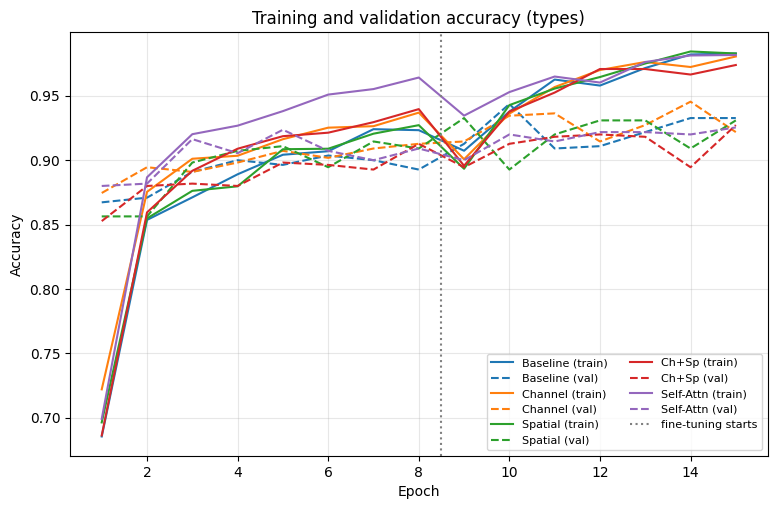

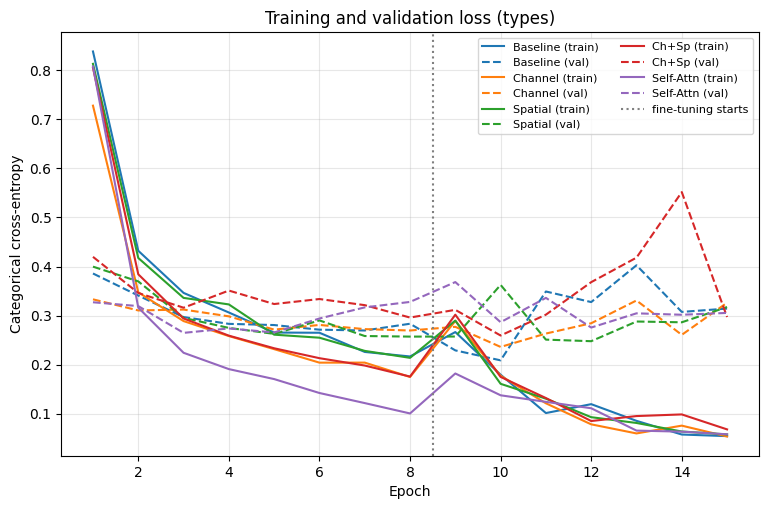

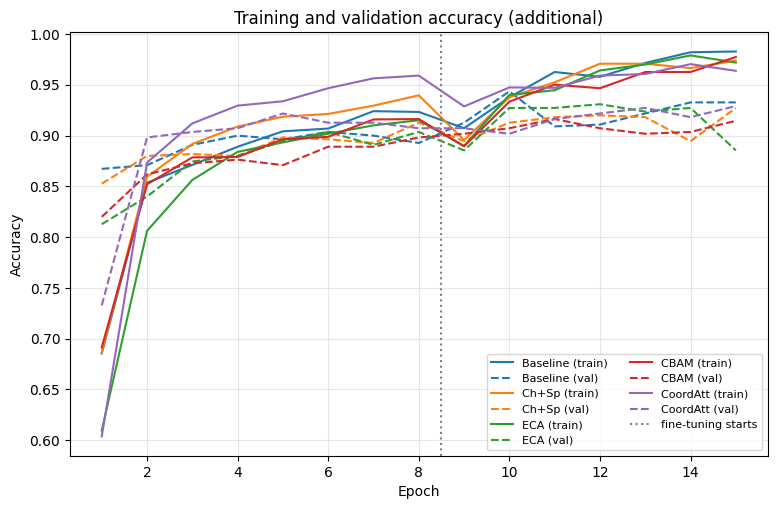

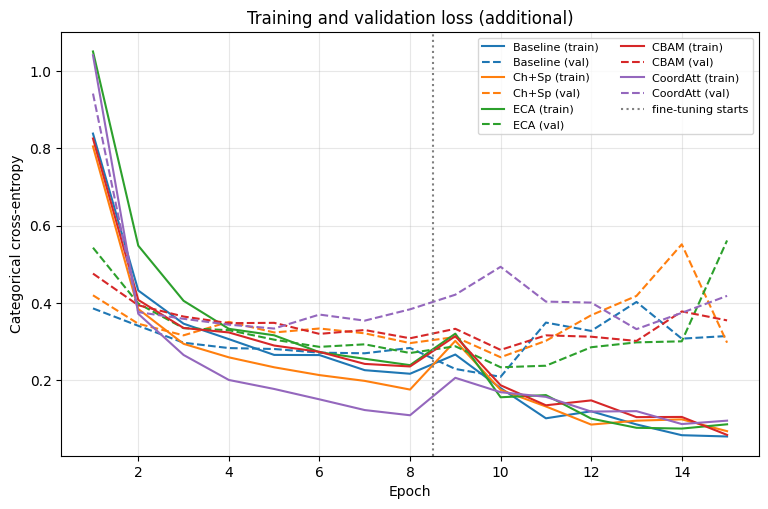

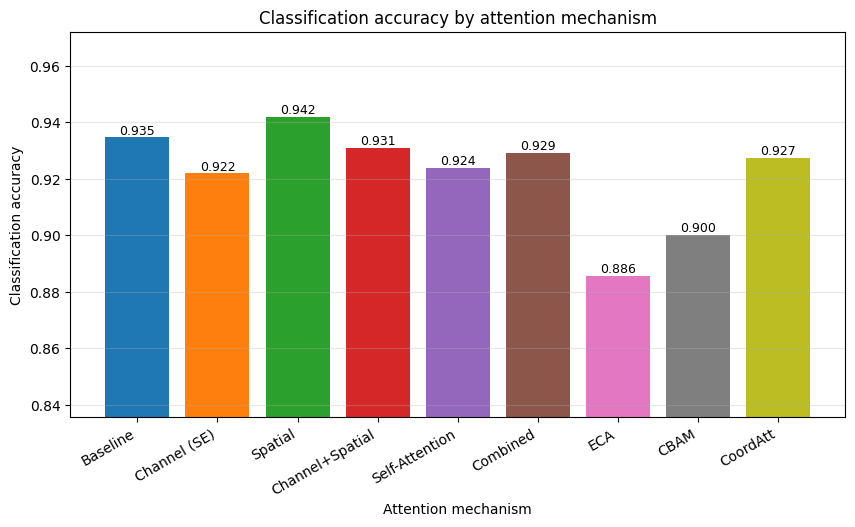

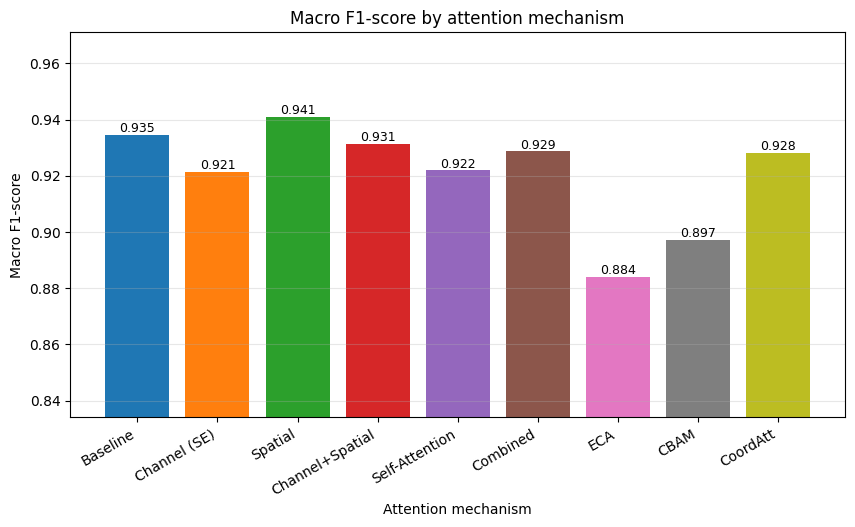

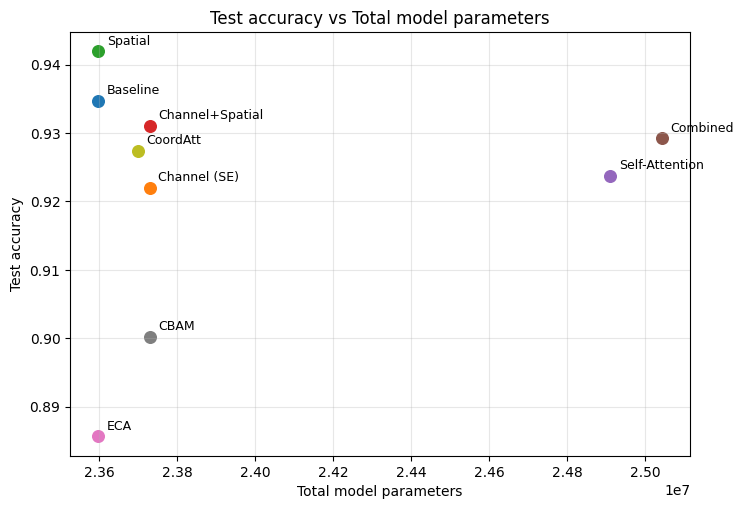

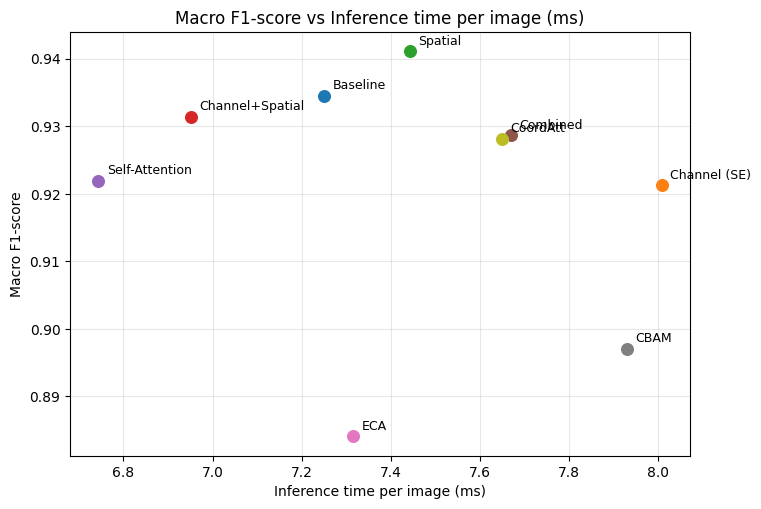

In [ ]:
SHORT = {'A0_Baseline': 'Baseline', 'A1_Channel_P3': 'Channel', 'A2_Spatial_P3': 'Spatial',
         'A3_ChSp_P3': 'Ch+Sp', 'A4_Self_P3': 'Self-Attn', 'A5_Combined_P3': 'Combined',
         'X1_ECA_P3': 'ECA', 'X2_CBAM_P3': 'CBAM', 'X3_CoordAtt_P3': 'CoordAtt'}

def plot_curves(names, key, ylabel, title, fname):
    names = [n for n in names if n in results]
    cmap = plt.get_cmap('tab10')
    plt.figure(figsize=(9, 5.5))
    for i, n in enumerate(names):
        h = results[n]['history']
        ep = np.arange(1, len(h[key]) + 1)
        plt.plot(ep, h[key], color=cmap(i), label=f'{SHORT[n]} (train)')
        plt.plot(ep, h['val_' + key], color=cmap(i), ls='--', label=f'{SHORT[n]} (val)')
    plt.axvline(EPOCHS_HEAD + 0.5, color='gray', ls=':', label='fine-tuning starts')
    plt.xlabel('Epoch'); plt.ylabel(ylabel); plt.title(title); plt.grid(alpha=0.3)
    plt.legend(fontsize=8, ncol=2)
    savefig(fname); plt.show()

CURVE_SETS = [
    (['A0_Baseline', 'A1_Channel_P3', 'A2_Spatial_P3', 'A3_ChSp_P3', 'A4_Self_P3'], 'types'),
    (['A0_Baseline', 'A3_ChSp_P3', 'X1_ECA_P3', 'X2_CBAM_P3', 'X3_CoordAtt_P3'], 'additional'),
]
for names, tag in CURVE_SETS:
    plot_curves(names, 'accuracy', 'Accuracy', f'Training and validation accuracy ({tag})', f'02_acc_curves_{tag}')
    plot_curves(names, 'loss', 'Categorical cross-entropy', f'Training and validation loss ({tag})', f'03_loss_curves_{tag}')

MECH = [('Baseline', 'A0_Baseline'), ('Channel (SE)', 'A1_Channel_P3'), ('Spatial', 'A2_Spatial_P3'),
        ('Channel+Spatial', 'A3_ChSp_P3'), ('Self-Attention', 'A4_Self_P3'), ('Combined', 'A5_Combined_P3'),
        ('ECA', 'X1_ECA_P3'), ('CBAM', 'X2_CBAM_P3'), ('CoordAtt', 'X3_CoordAtt_P3')]
MECH = [(l, n) for l, n in MECH if n in results]

def bar_metric(key, ylabel, fname):
    labs = [l for l, _ in MECH]
    vals = [results[n][key] for _, n in MECH]
    plt.figure(figsize=(10, 5))
    bars = plt.bar(labs, vals, color=plt.get_cmap('tab10')(np.arange(len(labs)) % 10))
    for b, v in zip(bars, vals):
        plt.text(b.get_x() + b.get_width() / 2, v, f'{v:.3f}', ha='center', va='bottom', fontsize=9)
    plt.ylim(max(0, min(vals) - 0.05), min(1.0, max(vals) + 0.03))
    plt.ylabel(ylabel); plt.xlabel('Attention mechanism'); plt.xticks(rotation=30, ha='right')
    plt.title(f'{ylabel} by attention mechanism'); plt.grid(axis='y', alpha=0.3)
    savefig(fname); plt.show()

bar_metric('test_acc', 'Classification accuracy', '04_bar_accuracy')
bar_metric('f1', 'Macro F1-score', '05_bar_macro_f1')

def scatter_metric(xkey, ykey, xlabel, ylabel, fname):
    plt.figure(figsize=(8, 5.5))
    for l, n in MECH:
        x, y = results[n][xkey], results[n][ykey]
        plt.scatter(x, y, s=70)
        plt.annotate(l, (x, y), textcoords='offset points', xytext=(6, 5), fontsize=9)
    plt.xlabel(xlabel); plt.ylabel(ylabel); plt.title(f'{ylabel} vs {xlabel}'); plt.grid(alpha=0.3)
    savefig(fname); plt.show()

scatter_metric('params_total', 'test_acc', 'Total model parameters', 'Test accuracy', '06_scatter_acc_params')
scatter_metric('infer_ms', 'f1', 'Inference time per image (ms)', 'Macro F1-score', '07_scatter_f1_time')

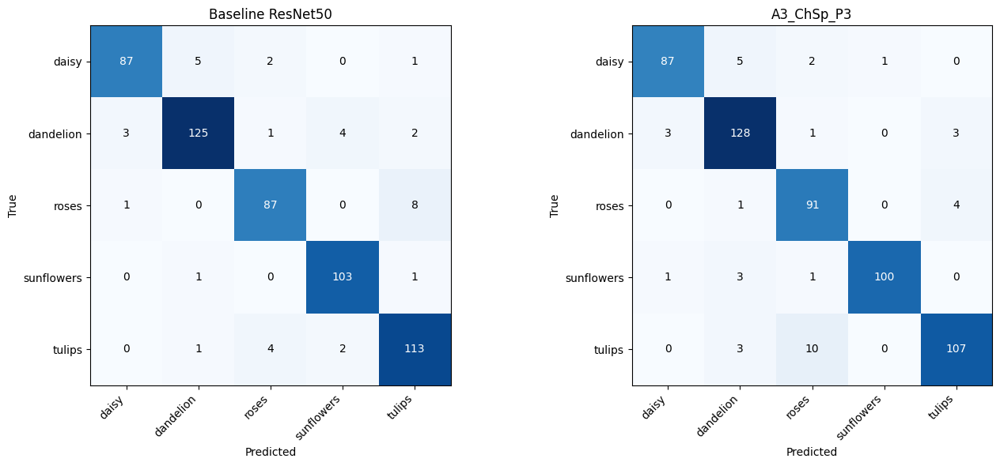


--- Class-wise report: A0_Baseline ---
              precision    recall  f1-score   support

       daisy     0.9560    0.9158    0.9355        95
   dandelion     0.9470    0.9259    0.9363       135
       roses     0.9255    0.9062    0.9158        96
  sunflowers     0.9450    0.9810    0.9626       105
      tulips     0.9040    0.9417    0.9224       120

    accuracy                         0.9347       551
   macro avg     0.9355    0.9341    0.9345       551
weighted avg     0.9351    0.9347    0.9346       551


--- Class-wise report: A3_ChSp_P3 ---
              precision    recall  f1-score   support

       daisy     0.9560    0.9158    0.9355        95
   dandelion     0.9143    0.9481    0.9309       135
       roses     0.8667    0.9479    0.9055        96
  sunflowers     0.9901    0.9524    0.9709       105
      tulips     0.9386    0.8917    0.9145       120

    accuracy                         0.9310       551
   macro avg     0.9331    0.9312    0.9315       55

In [ ]:
SELECTED = 'A3_ChSp_P3'     # attention model used for the confusion matrix / Grad-CAM comparisons

def plot_cm(ax, cm, title):
    cm = np.array(cm)
    im = ax.imshow(cm, cmap='Blues')
    ax.set_xticks(range(NUM_CLASSES)); ax.set_yticks(range(NUM_CLASSES))
    ax.set_xticklabels(CLASS_NAMES, rotation=45, ha='right'); ax.set_yticklabels(CLASS_NAMES)
    ax.set_xlabel('Predicted'); ax.set_ylabel('True'); ax.set_title(title)
    thr = cm.max() / 2.0
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            ax.text(j, i, int(cm[i, j]), ha='center', va='center',
                    color='white' if cm[i, j] > thr else 'black')

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
plot_cm(axes[0], results['A0_Baseline']['cm'], 'Baseline ResNet50')
plot_cm(axes[1], results[SELECTED]['cm'], f'{SELECTED}')
plt.tight_layout(); savefig('08_confusion_matrices'); plt.show()

for n in ['A0_Baseline', SELECTED]:
    print(f'\n--- Class-wise report: {n} ---')
    print(classification_report(y_test, results[n]['y_pred'], target_names=CLASS_NAMES, digits=4, zero_division=0))

In [ ]:
VIZ_MODELS = ['A0_Baseline', 'A1_Channel_P3', 'A2_Spatial_P3', 'A3_ChSp_P3', 'A4_Self_P3',
              'B2_ChSp_P2', 'B4_ChSp_P4', 'X1_ECA_P3', 'X2_CBAM_P3', 'X3_CoordAtt_P3']

keras.backend.clear_session(); gc.collect()
MODELS, PROBES, GRADMODELS = {}, {}, {}
for n in VIZ_MODELS:
    if n in results:
        m = build_model(EXPERIMENTS[n], pretrained=False)
        m.load_weights(f'{WEIGHT_DIR}/{n}.weights.h5')
        MODELS[n] = m
print('Loaded:', list(MODELS.keys()))

# ---------- helpers ----------
def run_probe(mname, lnames, idx):
    key = (mname, tuple(lnames))
    if key not in PROBES:
        m = MODELS[mname]
        PROBES[key] = keras.Model(m.input, [m.get_layer(n).output for n in lnames])
    outs = PROBES[key](X_test[idx:idx + 1].astype(np.float32), training=False)
    if not isinstance(outs, (list, tuple)):
        outs = [outs]
    return [np.asarray(o) for o in outs]

def norm01(m):
    m = np.asarray(m, dtype=np.float32)
    return (m - m.min()) / (m.max() - m.min() + 1e-8)

def resize_map(m):
    m = np.asarray(m, dtype=np.float32)
    r = tf.image.resize(m[..., None], (IMG_SIZE, IMG_SIZE)).numpy()[..., 0]
    return norm01(r)

def show_overlay(ax, img, heat, alpha=0.45):
    ax.imshow(img.astype(np.uint8))
    ax.imshow(resize_map(heat), cmap='jet', alpha=alpha, vmin=0, vmax=1)
    ax.axis('off')

def gradcam(mname, img_uint8, class_idx=None):
    if mname not in GRADMODELS:
        m = MODELS[mname]
        GRADMODELS[mname] = keras.Model(m.input, [m.get_layer('feat_last').output, m.output])
    gm = GRADMODELS[mname]
    x = tf.convert_to_tensor(img_uint8[None].astype(np.float32))
    with tf.GradientTape() as tape:
        tape.watch(x)
        fmap, preds = gm(x, training=False)
        if class_idx is None:
            class_idx = int(tf.argmax(preds[0]))
        score = preds[:, class_idx]
    grads = tape.gradient(score, fmap)
    alpha = tf.reduce_mean(grads, axis=(1, 2), keepdims=True)
    cam = tf.nn.relu(tf.reduce_sum(alpha * fmap, axis=-1))[0].numpy()
    return norm01(cam), class_idx

def selfattn_map(mname, idx, mode='mean'):
    layer = MODELS[mname].get_layer('attP3_self')
    feat = run_probe(mname, ['conv4_block6_out'], idx)[0]
    A = layer.attention_matrix(tf.constant(feat)).numpy()[0]
    h, w = layer.h, layer.w
    if mode == 'mean':
        m = A.mean(axis=0)
    elif mode == 'max':
        m = A.max(axis=0)
    else:
        m = A[(h // 2) * w + (w // 2)]
    return m.reshape(h, w)

def grid(columns, idxs, fname, row_tags=None):
    """columns: (header, kind, model_name[, option])"""
    columns = [c for c in columns if c[1] == 'input' or c[2] in MODELS]
    nr, nc = len(idxs), len(columns)
    fig, axes = plt.subplots(nr, nc, figsize=(3.0 * nc, 3.3 * nr), squeeze=False)
    for r, idx in enumerate(idxs):
        img = X_test[idx]
        for c, col in enumerate(columns):
            header, kind, mname = col[0], col[1], col[2]
            opt = col[3] if len(col) > 3 else None
            ax = axes[r][c]; sub = ''
            if kind == 'input':
                ax.imshow(img); ax.axis('off')
                sub = f'true: {CLASS_NAMES[y_test[idx]]}'
                if row_tags: sub += f' ({row_tags[r]})'
            elif kind == 'gradcam':
                cam, cls = gradcam(mname, img)
                show_overlay(ax, img, cam); sub = f'pred: {CLASS_NAMES[cls]}'
            elif kind == 'spatial_overlay':
                m = run_probe(mname, [f'{opt or "attP3"}_sp_map'], idx)[0][0, :, :, 0]
                show_overlay(ax, img, m)
            elif kind == 'spatial_raw':
                m = run_probe(mname, [f'{opt or "attP3"}_sp_map'], idx)[0][0, :, :, 0]
                ax.imshow(resize_map(m), cmap='jet', vmin=0, vmax=1); ax.axis('off')
            elif kind == 'selfattn':
                mode = opt or 'mean'
                m = selfattn_map(mname, idx, mode)
                show_overlay(ax, img, m)
                if mode == 'query':
                    h, w = m.shape
                    ax.plot((w // 2 + 0.5) / w * IMG_SIZE, (h // 2 + 0.5) / h * IMG_SIZE, 'w*', ms=14, mec='k')
            ax.set_title(f'{header}\n{sub}' if sub else header, fontsize=9)
    plt.tight_layout(); savefig(fname); plt.show()

Loaded: ['A0_Baseline', 'A1_Channel_P3', 'A2_Spatial_P3', 'A3_ChSp_P3', 'A4_Self_P3', 'B2_ChSp_P2', 'B4_ChSp_P4', 'X1_ECA_P3', 'X2_CBAM_P3', 'X3_CoordAtt_P3']


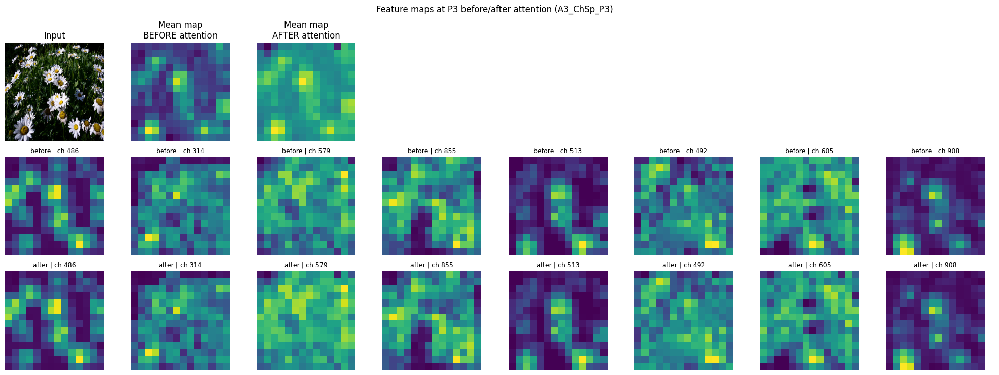

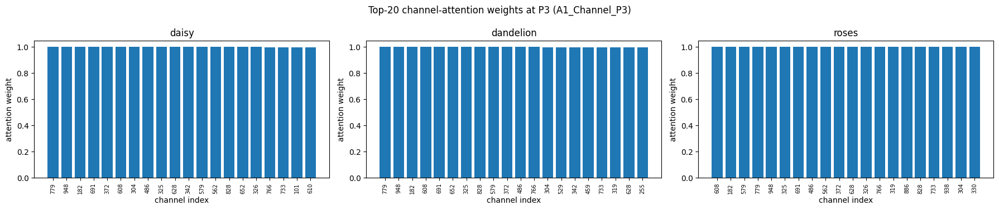

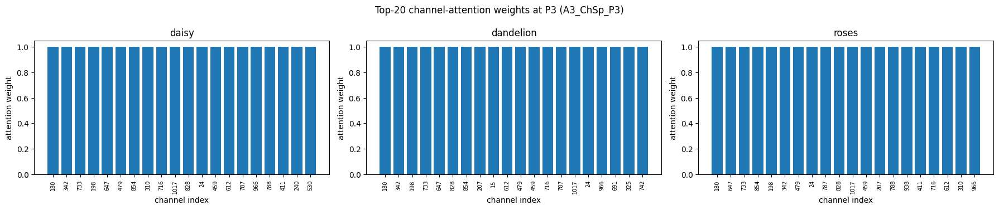

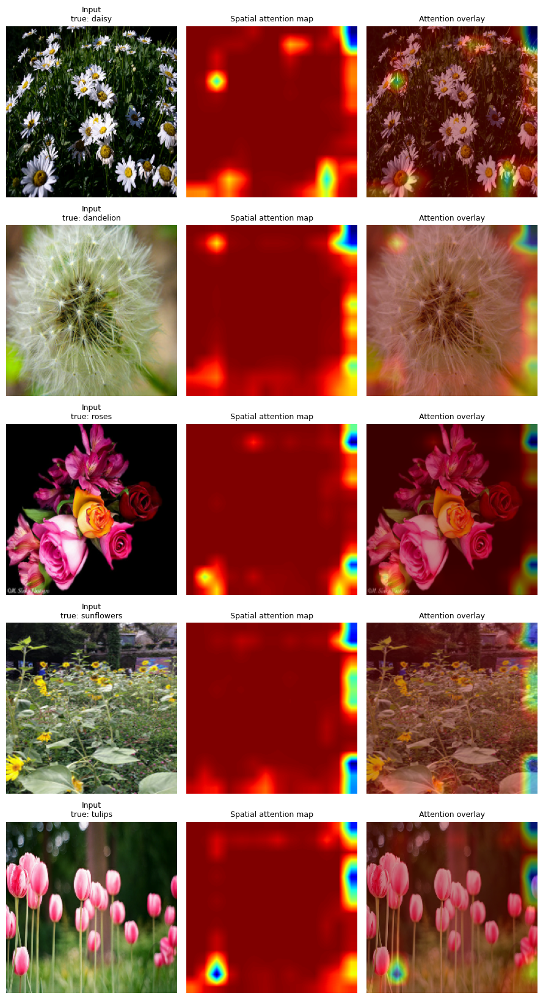

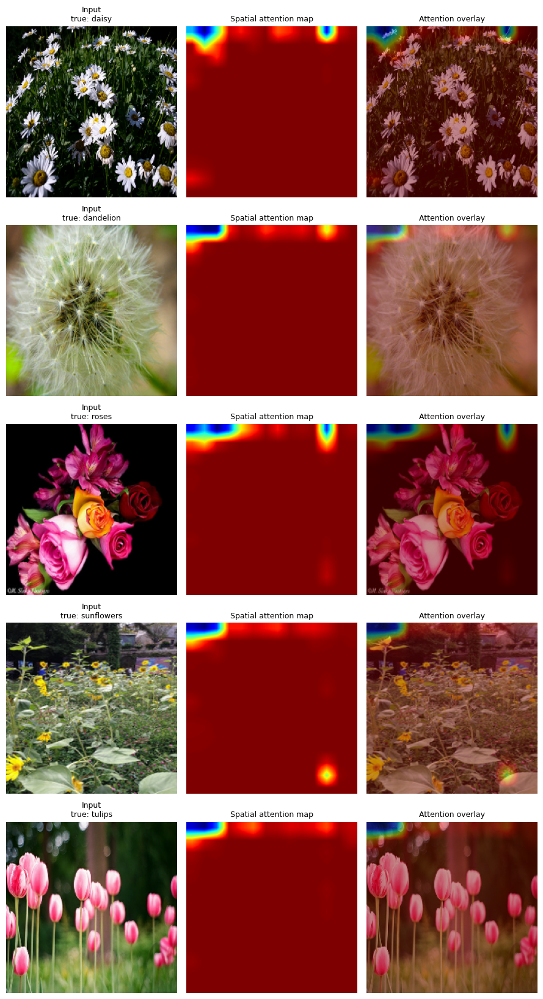

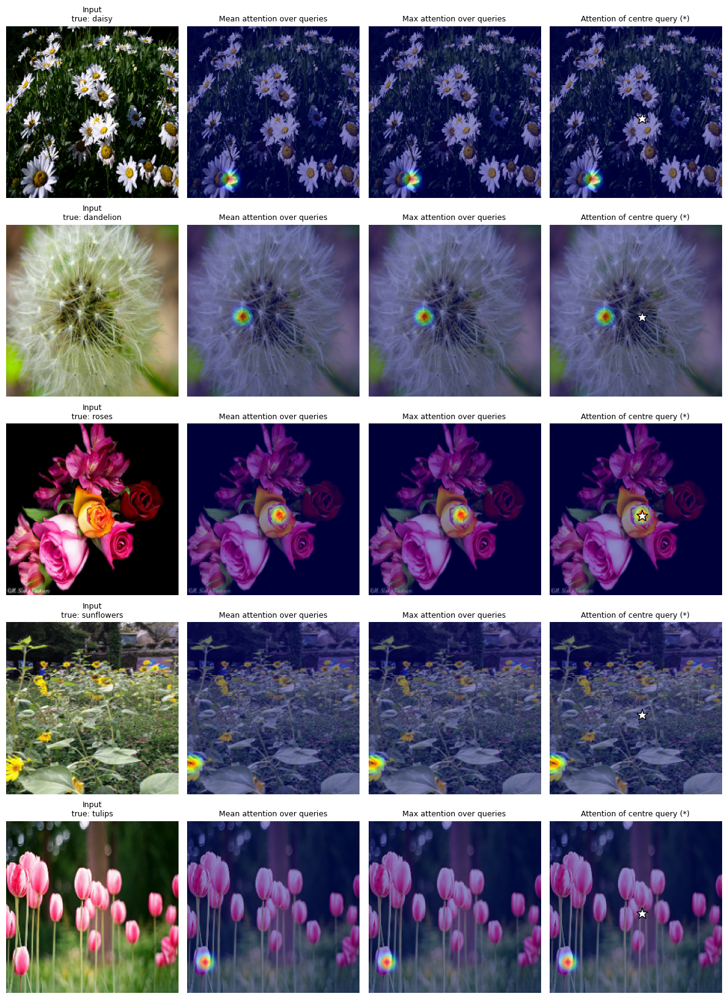

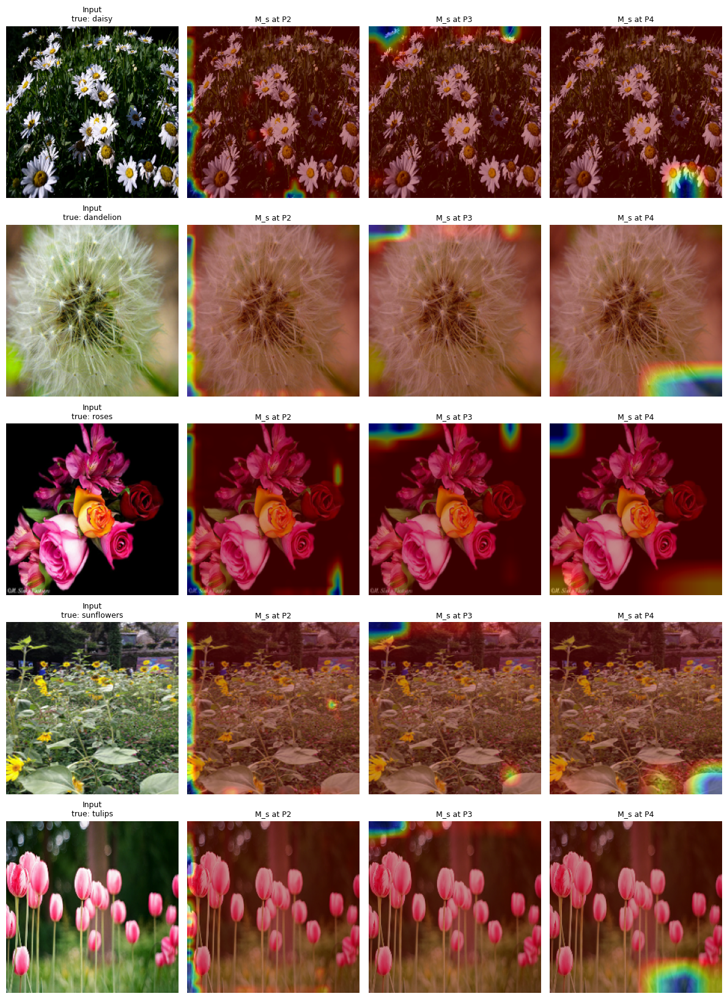

In [ ]:
# ---- (5, 10) feature maps before and after attention (selected model, P3) ----
idx = REP_IDX[0]
pre, post = run_probe(SELECTED, ['conv4_block6_out', 'attP3_post'], idx)
pre, post = pre[0], post[0]
top = np.argsort(-pre.mean(axis=(0, 1)))[:8]
fig, axes = plt.subplots(3, 8, figsize=(20, 7.5))
for ax in axes.ravel(): ax.axis('off')
axes[0][0].imshow(X_test[idx]); axes[0][0].set_title('Input')
axes[0][1].imshow(norm01(pre.mean(axis=-1)), cmap='viridis'); axes[0][1].set_title('Mean map\nBEFORE attention')
axes[0][2].imshow(norm01(post.mean(axis=-1)), cmap='viridis'); axes[0][2].set_title('Mean map\nAFTER attention')
for j, ch in enumerate(top):
    axes[1][j].imshow(pre[:, :, ch], cmap='viridis'); axes[1][j].set_title(f'before | ch {ch}', fontsize=9)
    axes[2][j].imshow(post[:, :, ch], cmap='viridis'); axes[2][j].set_title(f'after | ch {ch}', fontsize=9)
plt.suptitle(f'Feature maps at P3 before/after attention ({SELECTED})')
plt.tight_layout(); savefig('09_feature_maps_before_after'); plt.show()

# ---- (6) channel-attention weights: top-K = 20, three different images ----
K_TOP = 20
for mname in ['A1_Channel_P3', 'A3_ChSp_P3']:
    if mname not in MODELS: continue
    fig, axes = plt.subplots(1, 3, figsize=(18, 3.8))
    for ax, i in zip(axes, REP_IDX[:3]):
        w = run_probe(mname, ['attP3_chan_map'], i)[0].reshape(-1)
        t = np.argsort(-w)[:K_TOP]
        ax.bar(range(K_TOP), w[t])
        ax.set_xticks(range(K_TOP)); ax.set_xticklabels(t, rotation=90, fontsize=7)
        ax.set_xlabel('channel index'); ax.set_ylabel('attention weight')
        ax.set_title(f'{CLASS_NAMES[y_test[i]]}')
    plt.suptitle(f'Top-{K_TOP} channel-attention weights at P3 ({mname})')
    plt.tight_layout(); savefig(f'10_channel_weights_{mname}'); plt.show()

# ---- (7, 8) spatial-attention heatmap and overlay (P3) ----
for mname in ['A2_Spatial_P3', 'A3_ChSp_P3']:
    grid([('Input', 'input', mname),
          ('Spatial attention map', 'spatial_raw', mname),
          ('Attention overlay', 'spatial_overlay', mname)],
         REP_IDX, f'11_spatial_attention_{mname}')

# ---- (9) self-attention response (A4, P3) ----
grid([('Input', 'input', 'A4_Self_P3'),
      ('Mean attention over queries', 'selfattn', 'A4_Self_P3', 'mean'),
      ('Max attention over queries', 'selfattn', 'A4_Self_P3', 'max'),
      ('Attention of centre query (*)', 'selfattn', 'A4_Self_P3', 'query')],
     REP_IDX, '12_self_attention_response')

# ---- (13) spatial attention at P2, P3, P4 for the same images ----
grid([('Input', 'input', 'A3_ChSp_P3'),
      ('M_s at P2', 'spatial_overlay', 'B2_ChSp_P2', 'attP2'),
      ('M_s at P3', 'spatial_overlay', 'A3_ChSp_P3', 'attP3'),
      ('M_s at P4', 'spatial_overlay', 'B4_ChSp_P4', 'attP4')],
     REP_IDX, '13_attention_maps_P2_P3_P4')

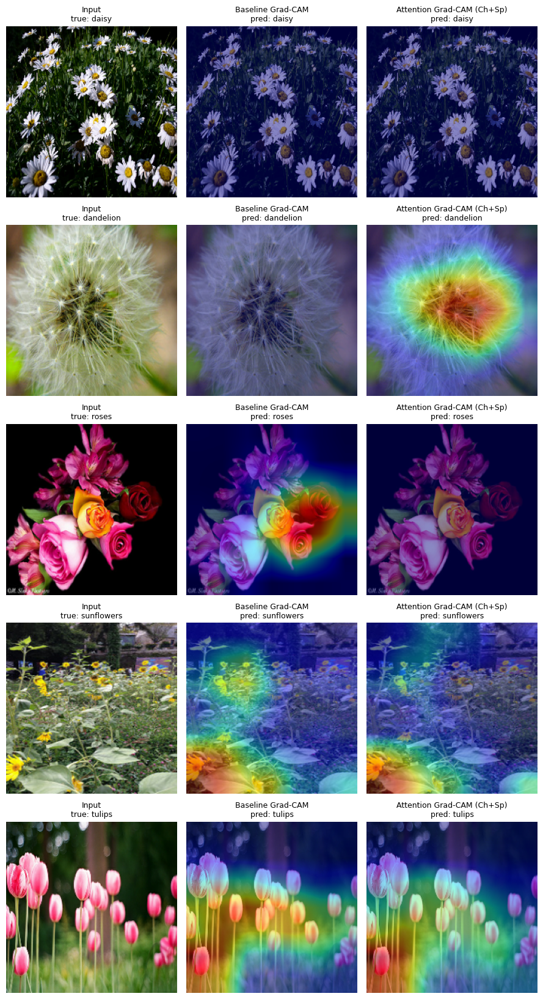

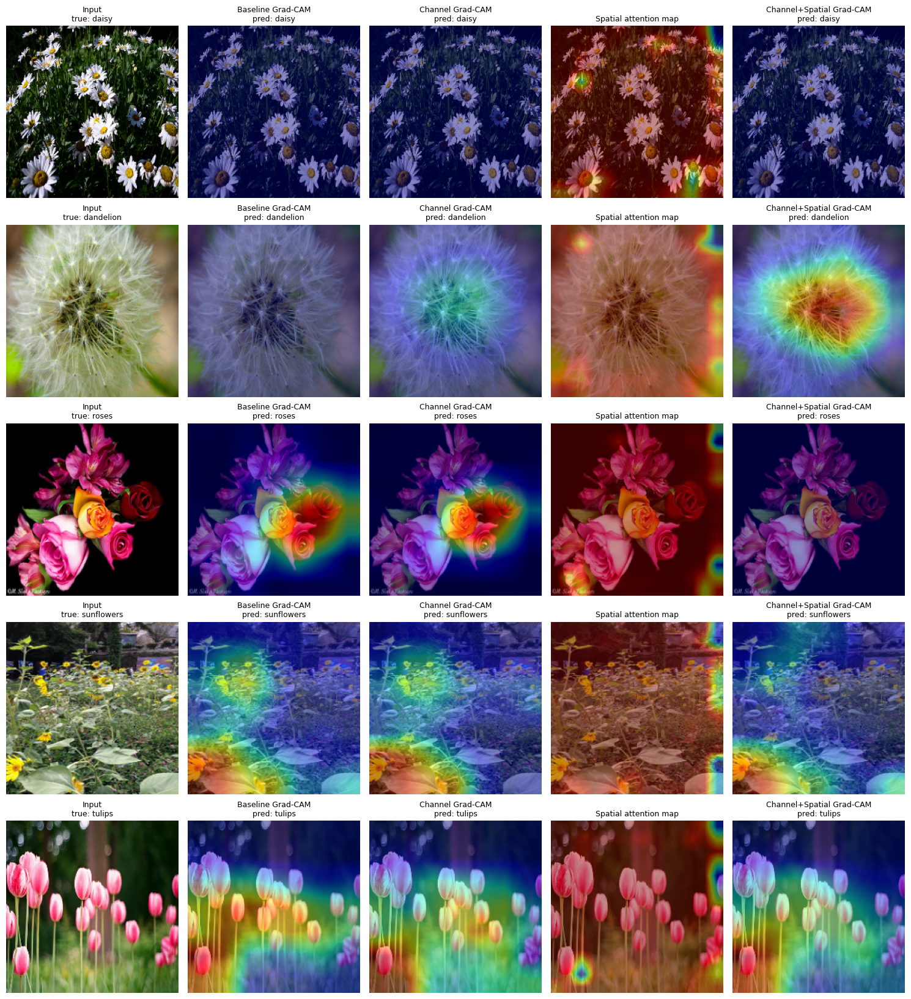

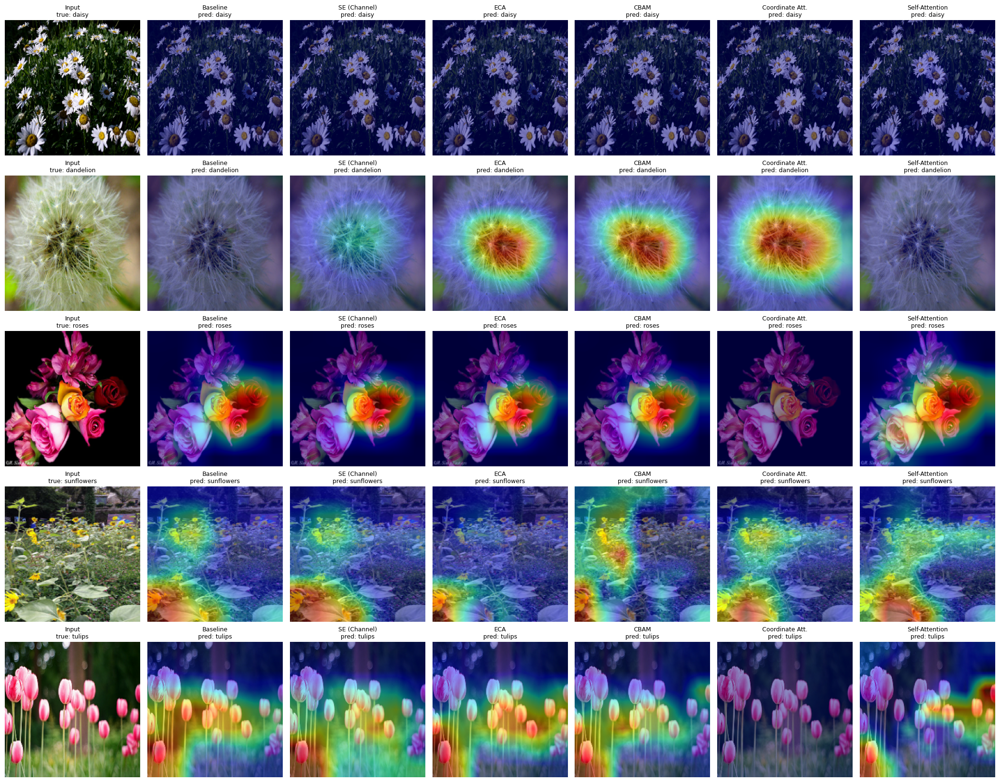

In [ ]:
# Input | Baseline Grad-CAM | Attention-model Grad-CAM
grid([('Input', 'input', 'A0_Baseline'),
      ('Baseline Grad-CAM', 'gradcam', 'A0_Baseline'),
      (f'Attention Grad-CAM ({SHORT[SELECTED]})', 'gradcam', SELECTED)],
     REP_IDX, '14_gradcam_baseline_vs_attention')

# Recommended layout: Input | Baseline | Channel | Spatial attention map | Channel+Spatial
grid([('Input', 'input', 'A0_Baseline'),
      ('Baseline Grad-CAM', 'gradcam', 'A0_Baseline'),
      ('Channel Grad-CAM', 'gradcam', 'A1_Channel_P3'),
      ('Spatial attention map', 'spatial_overlay', 'A2_Spatial_P3'),
      ('Channel+Spatial Grad-CAM', 'gradcam', 'A3_ChSp_P3')],
     REP_IDX, '15_gradcam_layout_main')

# Extended layout: Input | Baseline | SE | ECA | CBAM | Coordinate | Self-Attention (Grad-CAM for all)
grid([('Input', 'input', 'A0_Baseline'),
      ('Baseline', 'gradcam', 'A0_Baseline'),
      ('SE (Channel)', 'gradcam', 'A1_Channel_P3'),
      ('ECA', 'gradcam', 'X1_ECA_P3'),
      ('CBAM', 'gradcam', 'X2_CBAM_P3'),
      ('Coordinate Att.', 'gradcam', 'X3_CoordAtt_P3'),
      ('Self-Attention', 'gradcam', 'A4_Self_P3')],
     REP_IDX, '16_gradcam_layout_extended')

Selected test indices: [324, 534, 470, 404, 484] ['correct', 'correct', 'correct', 'incorrect', 'incorrect']


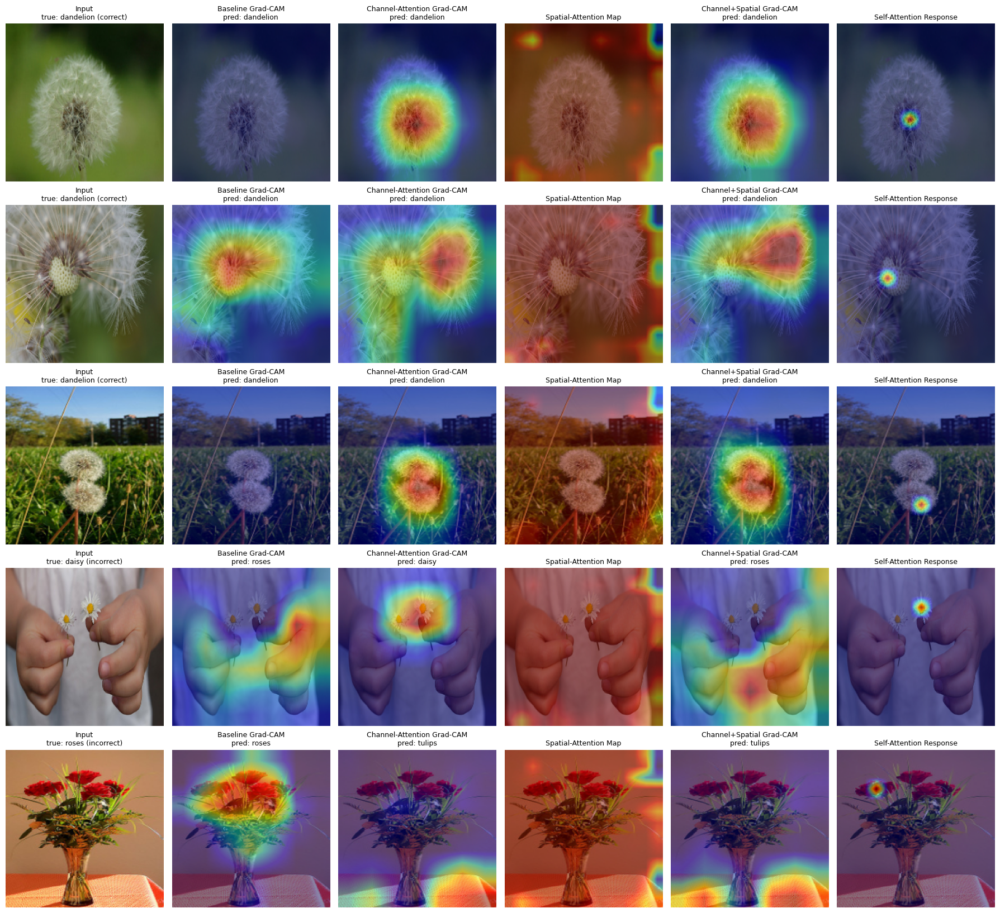

Figures saved in /content/figures


In [ ]:
pred_sel = np.array(results[SELECTED]['y_pred'])
pred_base = np.array(results['A0_Baseline']['y_pred'])
rng = np.random.RandomState(SEED)

correct = np.where(pred_sel == y_test)[0]
wrong = np.where(pred_sel != y_test)[0]
if len(wrong) < 2:                      # fall back to baseline errors if the attention model has < 2 errors
    wrong = np.union1d(wrong, np.where(pred_base != y_test)[0])

sel_c = [int(i) for i in rng.choice(correct, 3, replace=False)]
sel_w = [int(i) for i in rng.choice(wrong, min(2, len(wrong)), replace=False)] if len(wrong) else []
idxs = sel_c + sel_w
tags = ['correct'] * len(sel_c) + ['incorrect'] * len(sel_w)
print('Selected test indices:', idxs, tags)

grid([('Input', 'input', 'A0_Baseline'),
      ('Baseline Grad-CAM', 'gradcam', 'A0_Baseline'),
      ('Channel-Attention Grad-CAM', 'gradcam', 'A1_Channel_P3'),
      ('Spatial-Attention Map', 'spatial_overlay', 'A2_Spatial_P3'),
      ('Channel+Spatial Grad-CAM', 'gradcam', 'A3_ChSp_P3'),
      ('Self-Attention Response', 'selfattn', 'A4_Self_P3', 'mean')],
     idxs, '17_qualitative_comparison', row_tags=tags)

print('Figures saved in', FIG_DIR)